### Cell 1 — Install and import libraries ###
Run this cell if necessary. If you're using a virtual environment, make sure your Jupyter kernel uses that environment.

In [30]:

%pip install pandas numpy matplotlib seaborn pillow scikit-learn torch


Note: you may need to restart the kernel to use updated packages.


In [31]:

from pathlib import Path
from collections import defaultdict
import hashlib
import random

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from PIL import Image

from sklearn.model_selection import train_test_split

import torch

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

print("PyTorch version:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())


PyTorch version: 2.5.1+cu121
CUDA available: True


### Cell 2 — Configure the dataset paths ###
Your earlier output showed paths such as ..\archive\data\normal\N_101.jpg, so the following is a reasonable starting point. Change DATA_DIR if your notebook is saved in another directory.

In [32]:

DATA_DIR = Path(r"..\archive\data")
OUTPUT_DIR = Path("prepared_data")

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

CLASS_NAMES = [
    "glioma_tumor",
    "meningioma_tumor",
    "normal",
    "pituitary_tumor"
]

VALID_EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

print("Dataset directory:", DATA_DIR.resolve())
print("Directory exists:", DATA_DIR.is_dir())

for class_name in CLASS_NAMES:
    class_dir = DATA_DIR / class_name
    print(class_name, "->", class_dir.is_dir())


Dataset directory: C:\Users\rickv\School\Jaar3\minor\Challenge\Brain-Tumor\archive\Data
Directory exists: True
glioma_tumor -> True
meningioma_tumor -> True
normal -> True
pituitary_tumor -> True


### Cell 3 — Load the image inventory ### 
Each image's folder name becomes its label. We also record its relative path, extension and image dimensions.

In [33]:

records = []
unexpected_files = []

for class_name in CLASS_NAMES:
    class_dir = DATA_DIR / class_name

    if not class_dir.is_dir():
        raise FileNotFoundError(
            f"Class folder not found: {class_dir.resolve()}"
        )

    for path in sorted(class_dir.rglob("*")):
        if not path.is_file():
            continue

        if path.suffix.lower() not in VALID_EXTENSIONS:
            unexpected_files.append(str(path))
            continue

        try:
            with Image.open(path) as img:
                img.verify()

            with Image.open(path) as img:
                records.append({
                    "filepath": str(path.resolve()),
                    "filename": path.name,
                    "class": class_name,
                    "extension": path.suffix.lower(),
                    "width": img.width,
                    "height": img.height,
                    "mode": img.mode,
                    "format": img.format
                })

        except Exception as error:
            print(f"Unreadable image: {path} | {error}")

df = pd.DataFrame(records)

if df.empty:
    raise ValueError("No valid images were found.")

print("Total readable images:", len(df))
print("\nImages per class:")
print(df["class"].value_counts().reindex(CLASS_NAMES, fill_value=0))

print("\nImage formats:")
print(df["format"].value_counts())

print("\nImage modes:")
print(df["mode"].value_counts())

print("\nUnexpected files:", len(unexpected_files))


Total readable images: 3096

Images per class:
class
glioma_tumor        901
meningioma_tumor    913
normal              438
pituitary_tumor     844
Name: count, dtype: int64

Image formats:
format
JPEG    3096
Name: count, dtype: int64

Image modes:
mode
RGB    3096
Name: count, dtype: int64

Unexpected files: 0


### Cell 4 — Calculate hashes and identify duplicates ###
This uses SHA-256 to identify exact file duplicates. It is important to inspect label conflicts before removing any files.

In [34]:

def calculate_sha256(filepath):
    digest = hashlib.sha256()

    with open(filepath, "rb") as file:
        for chunk in iter(lambda: file.read(1024 * 1024), b""):
            digest.update(chunk)

    return digest.hexdigest()


df["sha256"] = df["filepath"].apply(calculate_sha256)

hash_groups = df.groupby("sha256", sort=False)

duplicate_groups = hash_groups.filter(
    lambda group: len(group) > 1
)

duplicate_group_count = int(
    (hash_groups.size() > 1).sum()
)

extra_copies = len(df) - df["sha256"].nunique()

conflicting_hashes = [
    digest
    for digest, group in hash_groups
    if group["class"].nunique() > 1
]

print("Original images:", len(df))
print("Unique file hashes:", df["sha256"].nunique())
print("Duplicate groups:", duplicate_group_count)
print("Extra duplicate copies:", extra_copies)
print("Groups with conflicting labels:", len(conflicting_hashes))


Original images: 3096
Unique file hashes: 2845
Duplicate groups: 217
Extra duplicate copies: 251
Groups with conflicting labels: 0


In [35]:

if conflicting_hashes:
    conflict_df = df[df["sha256"].isin(conflicting_hashes)]

    display(
        conflict_df[
            ["filename", "filepath", "class", "sha256"]
        ].sort_values("sha256")
    )

    raise ValueError(
        "Conflicting labels found for identical files. "
        "Investigate and resolve these before proceeding."
    )
else:
    print("No conflicting labels found for exact duplicates.")


No conflicting labels found for exact duplicates.


### Cell 5 — Create the cleaned dataset ###
Keep one representative file for each unique hash. The original files remain untouched.

In [36]:

unique_df = (
    df.sort_values("filepath")
      .drop_duplicates(subset="sha256", keep="first")
      .reset_index(drop=True)
)

print("Images before deduplication:", len(df))
print("Images after deduplication:", len(unique_df))
print("\nImages removed:", len(df) - len(unique_df))

print("\nCleaned class distribution:")
print(
    unique_df["class"]
    .value_counts()
    .reindex(CLASS_NAMES, fill_value=0)
)

unique_df.to_csv(
    OUTPUT_DIR / "unique_images.csv",
    index=False
)


Images before deduplication: 3096
Images after deduplication: 2845

Images removed: 251

Cleaned class distribution:
class
glioma_tumor        885
meningioma_tumor    816
normal              310
pituitary_tumor     834
Name: count, dtype: int64


### Cell 6 — Explore the cleaned class distribution ###
Deduplication may have changed the class counts, so check the distribution again before splitting.

,images,percentage
class,,
glioma_tumor,885,31.11
meningioma_tumor,816,28.68
normal,310,10.90
pituitary_tumor,834,29.31


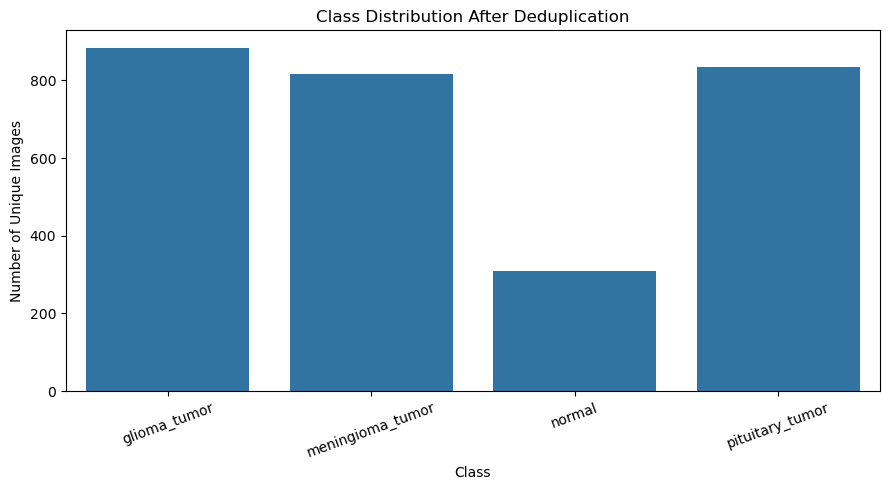

In [37]:

class_counts = (
    unique_df["class"]
    .value_counts()
    .reindex(CLASS_NAMES, fill_value=0)
)

class_summary = pd.DataFrame({
    "images": class_counts,
    "percentage": (class_counts / len(unique_df) * 100).round(2)
})

display(class_summary)

plt.figure(figsize=(9, 5))
sns.barplot(
    x=class_summary.index,
    y=class_summary["images"]
)

plt.title("Class Distribution After Deduplication")
plt.xlabel("Class")
plt.ylabel("Number of Unique Images")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()


### Cell 7 — Create fixed training, validation and test sets ###
Use 70% training, 15% validation and 15% test. The splits are stratified so that each class is represented proportionally.

In [38]:

train_df, temporary_df = train_test_split(
    unique_df,
    test_size=0.30,
    random_state=SEED,
    stratify=unique_df["class"]
)

val_df, test_df = train_test_split(
    temporary_df,
    test_size=0.50,
    random_state=SEED,
    stratify=temporary_df["class"]
)

# Add a split column and combine into one manifest
train_df = train_df.copy()
val_df = val_df.copy()
test_df = test_df.copy()

train_df["split"] = "train"
val_df["split"] = "validation"
test_df["split"] = "test"

splits_df = pd.concat(
    [train_df, val_df, test_df],
    ignore_index=True
)

print("Training:", len(train_df))
print("Validation:", len(val_df))
print("Test:", len(test_df))
print("Total:", len(splits_df))

display(
    pd.crosstab(
        splits_df["split"],
        splits_df["class"],
        margins=True
    )
)

splits_df.to_csv(
    OUTPUT_DIR / "data_splits.csv",
    index=False
)

train_df.to_csv(OUTPUT_DIR / "train.csv", index=False)
val_df.to_csv(OUTPUT_DIR / "validation.csv", index=False)
test_df.to_csv(OUTPUT_DIR / "test.csv", index=False)

print("Saved split manifests to:", OUTPUT_DIR.resolve())


Training: 1991
Validation: 427
Test: 427
Total: 2845


class,glioma_tumor,meningioma_tumor,normal,pituitary_tumor,All
split,,,,,
test,133,123,46,125,427
train,619,571,217,584,1991
validation,133,122,47,125,427
All,885,816,310,834,2845


Saved split manifests to: C:\Users\rickv\School\Jaar3\minor\Challenge\Brain-Tumor\brain_tumors\prepared_data


### Cell 8 — Check for data leakage ###
This checks that the same exact image hash doesn't occur in more than one split.

In [39]:

hashes_by_split = {
    split_name: set(group["sha256"])
    for split_name, group in splits_df.groupby("split")
}

assert hashes_by_split["train"].isdisjoint(
    hashes_by_split["validation"]
)
assert hashes_by_split["train"].isdisjoint(
    hashes_by_split["test"]
)
assert hashes_by_split["validation"].isdisjoint(
    hashes_by_split["test"]
)

assert len(splits_df) == len(unique_df)
assert splits_df["sha256"].nunique() == len(splits_df)

print("Checks passed: no exact-hash overlap between splits.")


Checks passed: no exact-hash overlap between splits.
